In [2]:
# Importing the proper and required data + visualization packages
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow
import numpy as np
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
import plotly.express as px
import seaborn as sns

In [3]:
try:
    test_data = pd.read_csv("handoff_data/fake_test_file.csv")
except FileNotFoundError:
    print("System Log: File not found. Please verify the directory path.")
except Exception as e:
    print(f"System Log: An unexpected error occurred -> {e}")

System Log: File not found. Please verify the directory path.


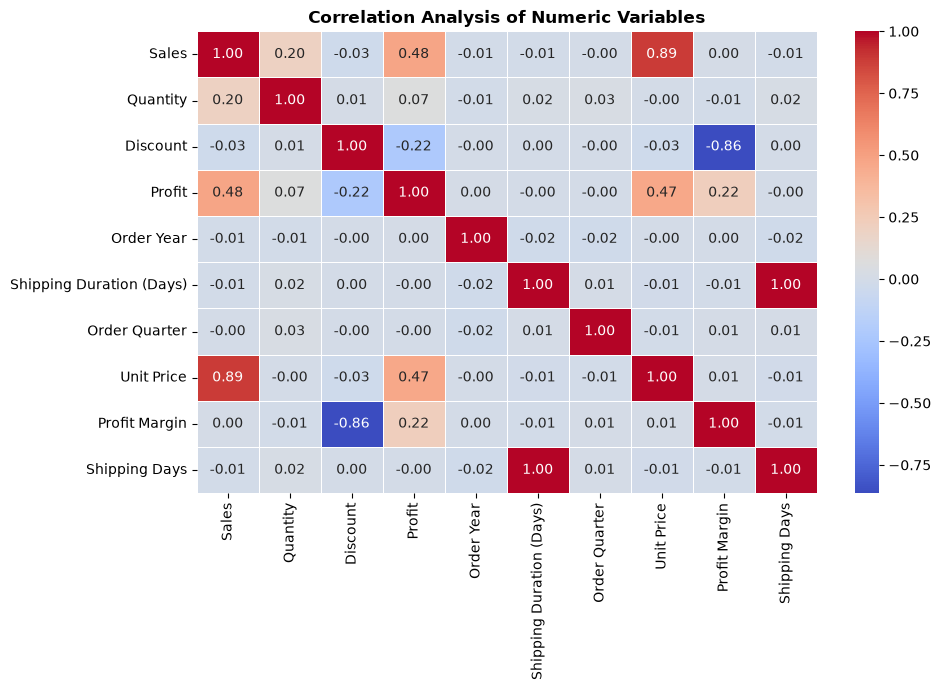

In [4]:
df_clean = pd.read_parquet("handoff_data/df_clean.parquet", engine="pyarrow")
numeric_cols = df_clean.select_dtypes(include=['number'])
plt.figure(figsize=(10, 6))
sns.heatmap(numeric_cols.corr(), annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Analysis of Numeric Variables", fontweight="bold")
plt.show()


In [5]:
df_clean = pd.read_parquet("handoff_data/df_clean.parquet", engine="pyarrow")
customer_features = pd.read_parquet("handoff_data/customer_features.parquet", engine="pyarrow")
product_features = pd.read_parquet("handoff_data/product_features.parquet", engine="pyarrow")
rfm = pd.read_parquet("handoff_data/rfm.parquet", engine="pyarrow")

In [6]:
rfm

,Recency,Frequency,Monetary
Customer ID,,,
AA-10315,185,5,5563.560
AA-10375,20,9,1056.390
AA-10480,260,4,1790.512
AA-10645,56,6,5086.935
AB-10015,416,3,886.156
...,...,...,...
XP-21865,44,11,2374.658
YC-21895,5,5,5454.350
YS-21880,10,8,6720.444


In [7]:
rfm.head()

,Recency,Frequency,Monetary
Customer ID,,,
AA-10315,185,5,5563.560
AA-10375,20,9,1056.390
AA-10480,260,4,1790.512
AA-10645,56,6,5086.935
AB-10015,416,3,886.156


In [8]:
state_profit = pd.read_csv("handoff_data/state_profit.csv", index_col="State")

In [9]:
discount_profit = pd.read_csv("handoff_data/discount_profit.csv", index_col="Discount Bucket", keep_default_na=False).squeeze('columns')

<Axes: xlabel='State'>

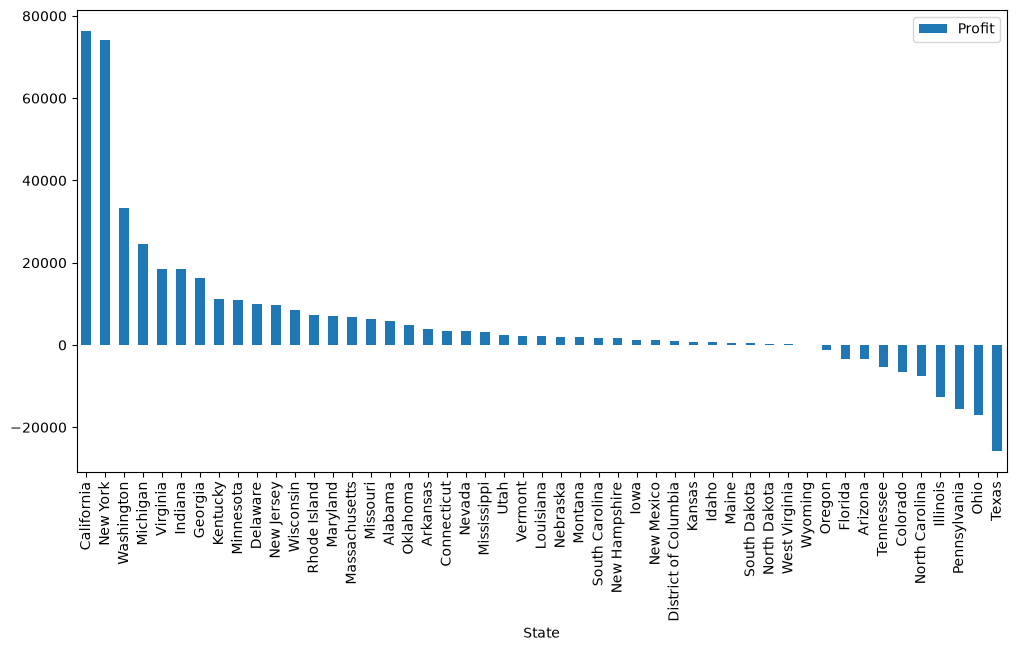

In [10]:
state_profit.plot(kind='bar', figsize=(12,6))

(0.0, 367096.56198)

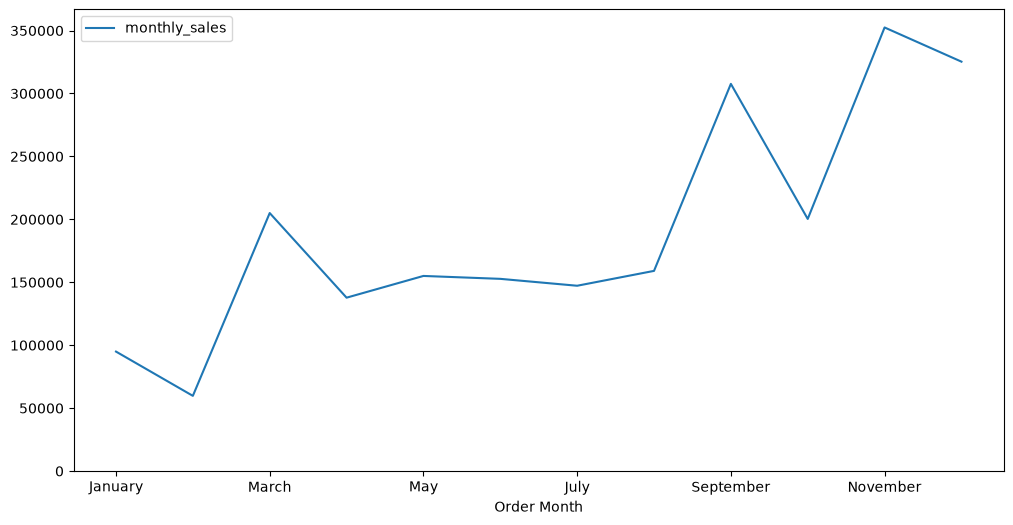

In [11]:
month_order = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]

df_clean.groupby("Order Month").agg(
    monthly_sales = ("Sales", "sum")
).reindex(month_order).plot(kind='line', figsize=(12,6))
plt.ylim(bottom=0)

In [12]:
df_clean.columns

Index(['Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID',
       'Customer Name', 'Segment', 'Country/Region', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit', 'Order Year',
       'Order Month', 'Order Day of Week', 'Shipping Duration (Days)',
       'Order Quarter', 'Is Weekend', 'Unit Price', 'Profit Margin',
       'Discount Bucket', 'Shipping Days', 'Order Weekday', 'IS Weekend'],
      dtype='str')

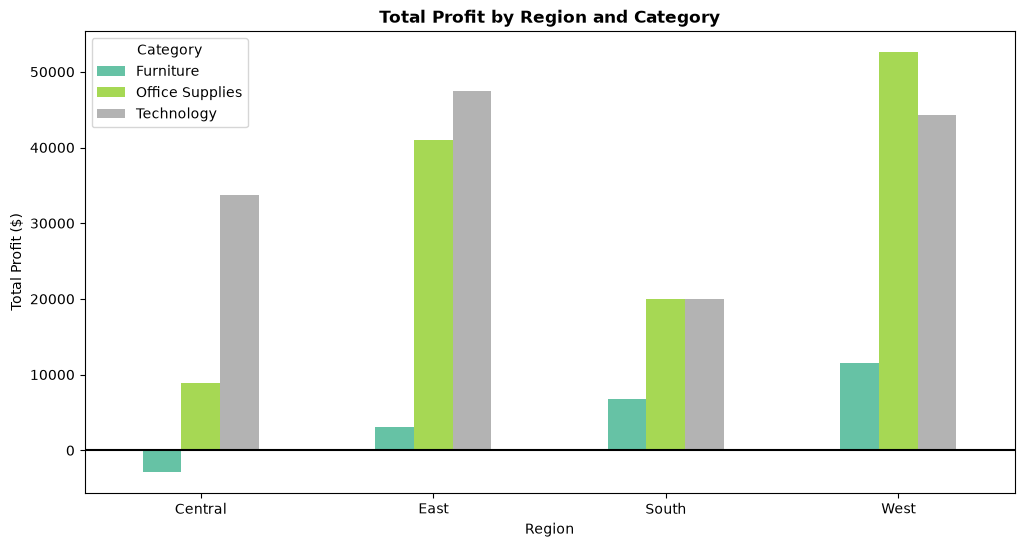

In [13]:
region_category_profit = df_clean.pivot_table(
    values="Profit", 
    index="Region", 
    columns="Category", 
    aggfunc="sum"
)

region_category_profit.plot(kind='bar', figsize=(12, 6), colormap='Set2')

plt.title("Total Profit by Region and Category", fontweight='bold')
plt.ylabel("Total Profit ($)")
plt.xlabel("Region")
plt.axhline(0, color='black', linewidth=1.5) 
plt.xticks(rotation=0)
plt.legend(title="Category")
plt.show()

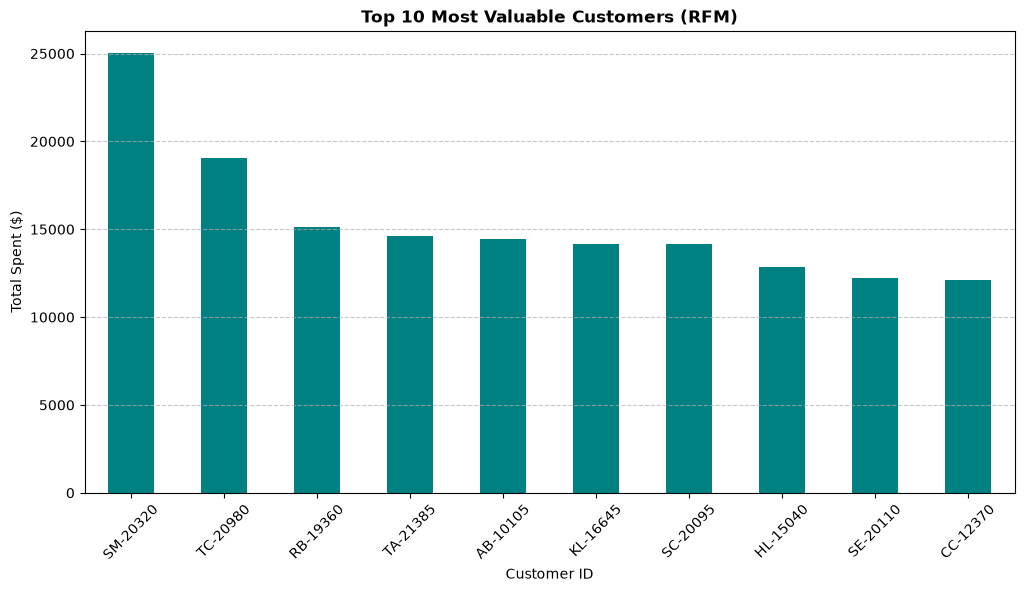

In [14]:
top_customers = rfm.sort_values('Monetary', ascending=False).head(10)

top_customers['Monetary'].plot(kind='bar', figsize=(12, 6), color='teal')

plt.title('Top 10 Most Valuable Customers (RFM)', fontweight='bold')
plt.xlabel('Customer ID')
plt.ylabel('Total Spent ($)')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [15]:
month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

(0.0, 405465.006295)

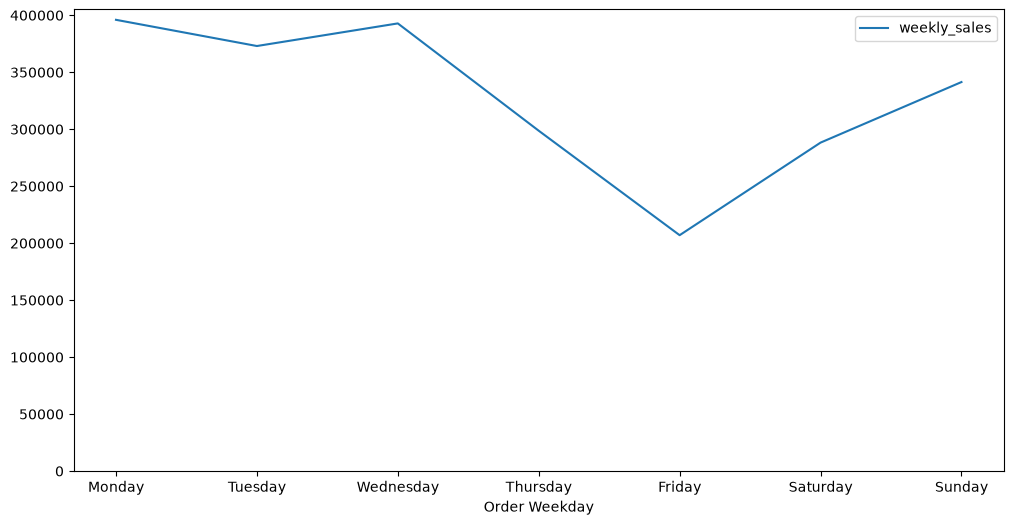

In [16]:
df_clean.groupby("Order Weekday").agg(
    weekly_sales = ("Sales", "sum")
).reindex(weekday_order).plot(kind='line', figsize=(12, 6))
plt.ylim(bottom=0)

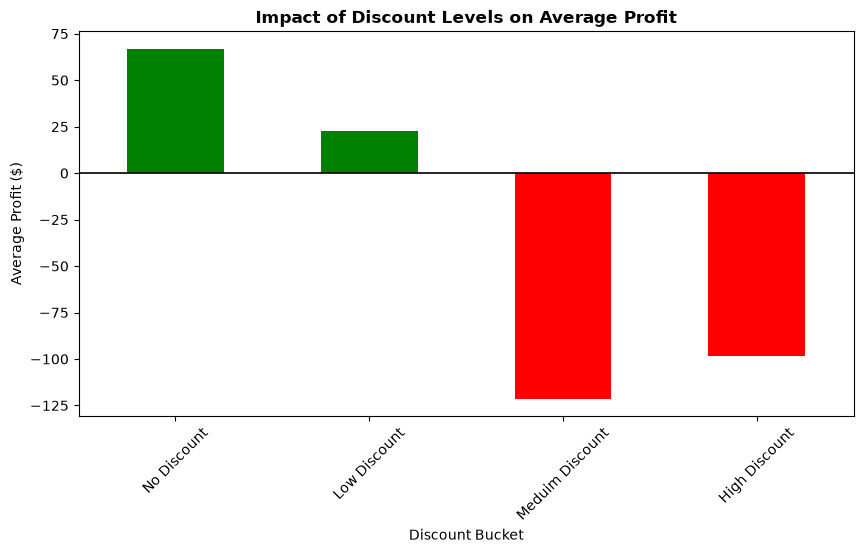

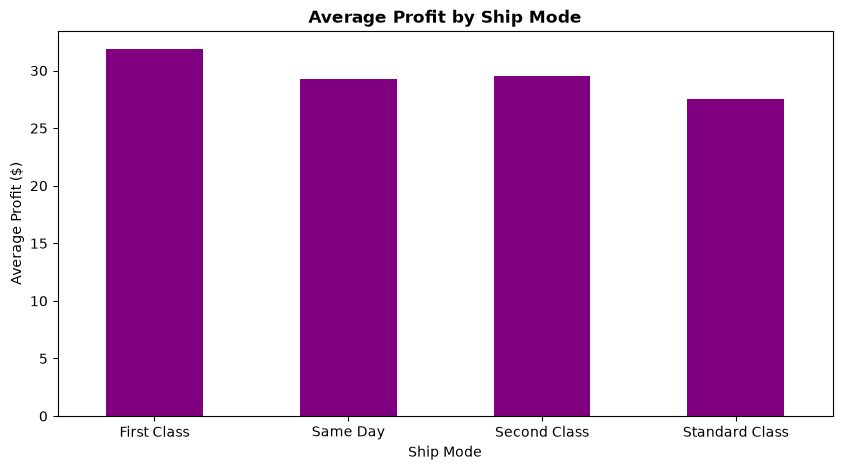

In [17]:
discount_profit.plot(kind='bar', figsize=(10, 5), color=['green', 'green', 'red', 'red'])
plt.title("Impact of Discount Levels on Average Profit", fontweight='bold')
plt.ylabel("Average Profit ($)")
plt.axhline(0, color='black', linewidth=1.2) 
plt.xticks(rotation=45)
plt.show()

ship_mode_summary = df_clean.groupby("Ship Mode")["Profit"].mean()

ship_mode_summary.plot(kind='bar', figsize=(10, 5), color='purple')
plt.title("Average Profit by Ship Mode", fontweight='bold')
plt.ylabel("Average Profit ($)")
plt.xticks(rotation=0)
plt.show()

(0.0, 367096.56198)

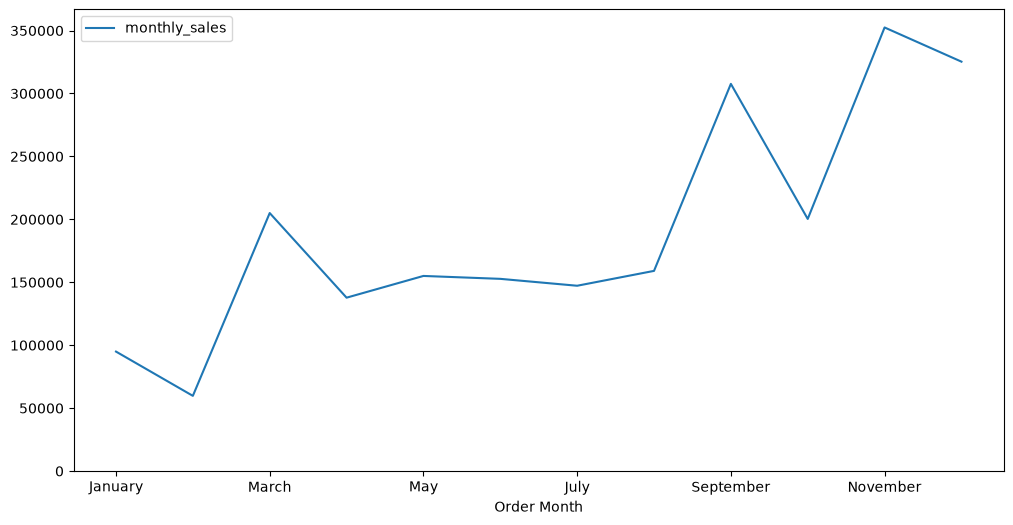

In [18]:
month_order = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]
df_clean.groupby("Order Month").agg(
    monthly_sales = ("Sales", "sum")
).reindex(month_order).plot(kind='line', figsize=(12, 6))
plt.ylim(bottom=0)

<Axes: xlabel='Order Month'>

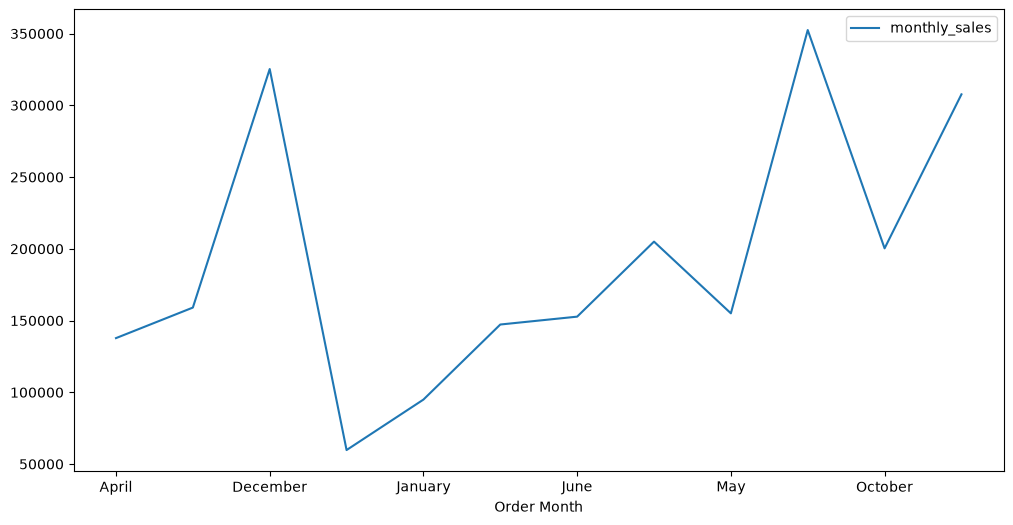

In [19]:
df_clean.groupby("Order Month").agg(
    monthly_sales = ("Sales", "sum")
).plot(kind='line', figsize=(12, 6))

In [20]:
ship_mode_summary = pd.read_csv("handoff_data/ship_mode_summary.csv", index_col="Ship Mode")
region_summary = pd.read_csv("handoff_data/region_summary.csv", index_col="Region")
category_summary = pd.read_csv("handoff_data/category_summary.csv", index_col="Category")
pivot = pd.read_csv("handoff_data/pivot_region_category.csv", index_col="Region")

In [21]:
# Shared palette: diverging (profit/loss), categorical (fixed order), accent
COLOR_POS = "#2E7D32"      # profit / gain
COLOR_NEG = "#C62828"      # loss
CATEGORICAL = ["#4C72B0", "#DD8452", "#55A868", "#8172B2"]
ACCENT = CATEGORICAL[1]    # used to call out weekends / peak months
INK = "#333333"
MUTED = "#7A7A7A"

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#CCCCCC",
    "axes.labelcolor": INK,
    "text.color": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "axes.grid": True,
    "grid.color": "#EAEAEA",
    "grid.linewidth": 0.8,
    "font.size": 10,
    "figure.facecolor": "white",
})


STATE_ABBREV = {
    "Alabama": "AL", "Arizona": "AZ", "Arkansas": "AR", "California": "CA",
    "Colorado": "CO", "Connecticut": "CT", "Delaware": "DE",
    "District Of Columbia": "DC", "Florida": "FL", "Georgia": "GA",
    "Idaho": "ID", "Illinois": "IL", "Indiana": "IN", "Iowa": "IA",
    "Kansas": "KS", "Kentucky": "KY", "Louisiana": "LA", "Maine": "ME",
    "Maryland": "MD", "Massachusetts": "MA", "Michigan": "MI",
    "Minnesota": "MN", "Mississippi": "MS", "Missouri": "MO",
    "Montana": "MT", "Nebraska": "NE", "Nevada": "NV",
    "New Hampshire": "NH", "New Jersey": "NJ", "New Mexico": "NM",
    "New York": "NY", "North Carolina": "NC", "North Dakota": "ND",
    "Ohio": "OH", "Oklahoma": "OK", "Oregon": "OR", "Pennsylvania": "PA",
    "Rhode Island": "RI", "South Carolina": "SC", "South Dakota": "SD",
    "Tennessee": "TN", "Texas": "TX", "Utah": "UT", "Vermont": "VT",
    "Virginia": "VA", "Washington": "WA", "West Virginia": "WV",
    "Wisconsin": "WI", "Wyoming": "WY",
}

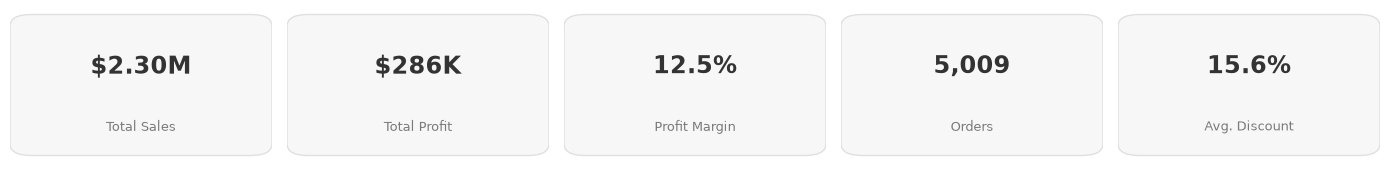

In [22]:
total_sales = df_clean["Sales"].sum()
total_profit = df_clean["Profit"].sum()
overall_margin = total_profit / total_sales * 100
total_orders = df_clean["Order ID"].nunique()
avg_discount = df_clean["Discount"].mean() * 100

kpis = [
    ("Total Sales", f"${total_sales/1e6:.2f}M"),
    ("Total Profit", f"${total_profit/1e3:.0f}K"),
    ("Profit Margin", f"{overall_margin:.1f}%"),
    ("Orders", f"{total_orders:,}"),
    ("Avg. Discount", f"{avg_discount:.1f}%"),
]

fig, axes = plt.subplots(1, 5, figsize=(14, 1.8))
for ax, (label, value) in zip(axes, kpis):
    ax.axis("off")
    ax.add_patch(FancyBboxPatch(
        (0.02, 0.05), 0.96, 0.9, boxstyle="round,pad=0.02,rounding_size=0.08",
        transform=ax.transAxes, facecolor="#F7F7F7", edgecolor="#E0E0E0", linewidth=1,
    ))
    ax.text(0.5, 0.62, value, transform=ax.transAxes, ha="center", va="center",
            fontsize=17, fontweight="bold", color=INK)
    ax.text(0.5, 0.22, label, transform=ax.transAxes, ha="center", va="center",
            fontsize=9.5, color=MUTED)
plt.tight_layout()
plt.show()

In [23]:
# 1b. Interactive Plotly version: every state at once, hover for the exact figure
sp_df = state_profit.reset_index()
sp_df.columns = ["State", "Profit"]
sp_df["Code"] = sp_df["State"].map(STATE_ABBREV)

fig_map = px.choropleth(
    sp_df,
    locations="Code",
    locationmode="USA-states",
    color="Profit",
    scope="usa",
    color_continuous_scale=[COLOR_NEG, "#F5F5F5", COLOR_POS],
    color_continuous_midpoint=0,
    hover_name="State",
    hover_data={"Code": False, "Profit": ":$,.0f"},
    title="Total Profit by State",
)
fig_map.update_layout(margin=dict(l=0, r=0, t=40, b=0))
fig_map.show()

In [24]:
df_clean["Discount Bucket"]

0           No Discount
1           No Discount
2           No Discount
3       Meduim Discount
4          Low Discount
             ...       
9989       Low Discount
9990        No Discount
9991       Low Discount
9992        No Discount
9993        No Discount
Name: Discount Bucket, Length: 9994, dtype: category
Categories (5, str): ['No Discount' < 'Low Discount' < 'Meduim Discount' < 'High Discount' < 'Extreme Discount']

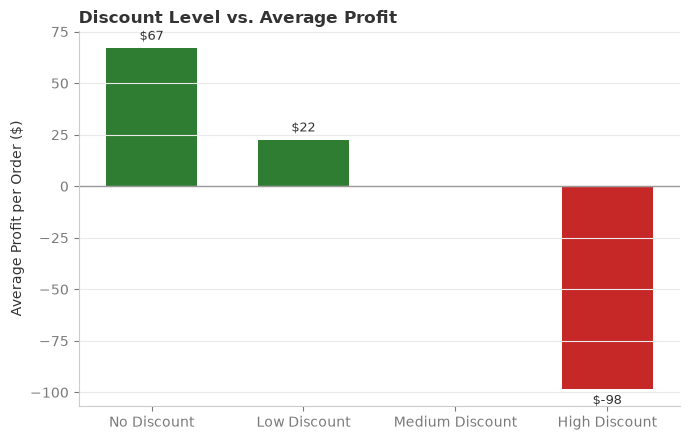

In [25]:
discount_order = ["No Discount", "Low Discount", "Medium Discount", "High Discount", "Very High Discount"]
dp = discount_profit.reindex(discount_order)
colors = [COLOR_POS if v >= 0 else COLOR_NEG for v in dp.values]

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(dp.index, dp.values, color=colors, width=0.6)
ax.axhline(0, color="#999999", linewidth=1)
ax.set_ylabel("Average Profit per Order ($)")
ax.set_title("Discount Level vs. Average Profit", loc="left", fontsize=12, fontweight="bold")
for bar, v in zip(bars, dp.values):
    if pd.isna(v):
        continue
    va = "bottom" if v >= 0 else "top"
    ax.annotate(f"${v:,.0f}", xy=(bar.get_x() + bar.get_width() / 2, v),
                xytext=(0, 4 if v >= 0 else -4), textcoords="offset points",
                ha="center", va=va, fontsize=9)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

In [26]:
df_clean[df_clean["Discount"] >= 0.8]["Order Date"].min()

Timestamp('2016-01-04 00:00:00')

In [27]:
df_clean[df_clean["Discount"] >= 0.8]["Order Date"].max()

Timestamp('2019-12-28 00:00:00')

In [28]:
ship_mode_summary = df_clean.groupby("Ship Mode", observed=True).agg(
    avg_profit=("Profit", "mean"),
    avg_shipping_days=("Shipping Duration (Days)", "mean")
)

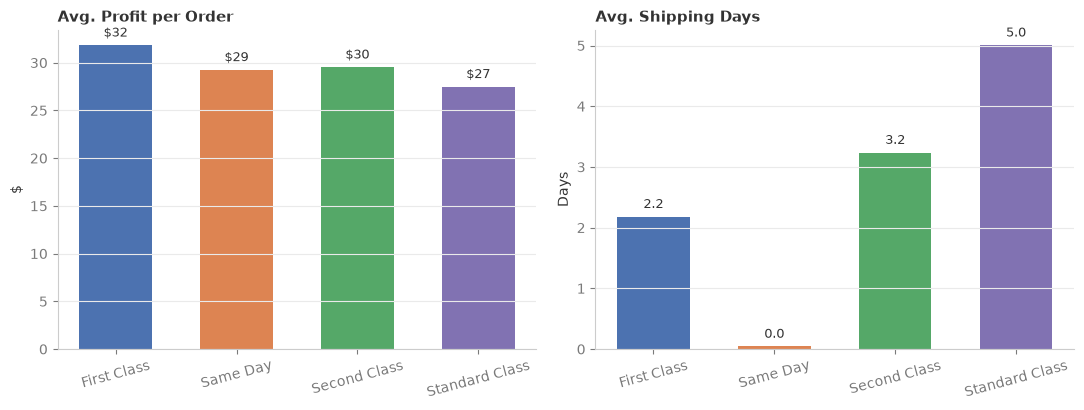

In [29]:
modes = ship_mode_summary.index.tolist()
mode_colors = CATEGORICAL[: len(modes)]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

ax = axes[0]
bars = ax.bar(modes, ship_mode_summary["avg_profit"], color=mode_colors, width=0.6)
ax.set_title("Avg. Profit per Order", loc="left", fontsize=11, fontweight="bold")
ax.set_ylabel("$")
for bar, v in zip(bars, ship_mode_summary["avg_profit"]):
    ax.annotate(f"${v:.0f}", xy=(bar.get_x() + bar.get_width() / 2, v),
                xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=9)
ax.grid(axis="x", visible=False)

ax = axes[1]
bars = ax.bar(modes, ship_mode_summary["avg_shipping_days"], color=mode_colors, width=0.6)
ax.set_title("Avg. Shipping Days", loc="left", fontsize=11, fontweight="bold")
ax.set_ylabel("Days")
for bar, v in zip(bars, ship_mode_summary["avg_shipping_days"]):
    ax.annotate(f"{v:.1f}", xy=(bar.get_x() + bar.get_width() / 2, v),
                xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=9)
ax.grid(axis="x", visible=False)

for a in axes:
    a.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

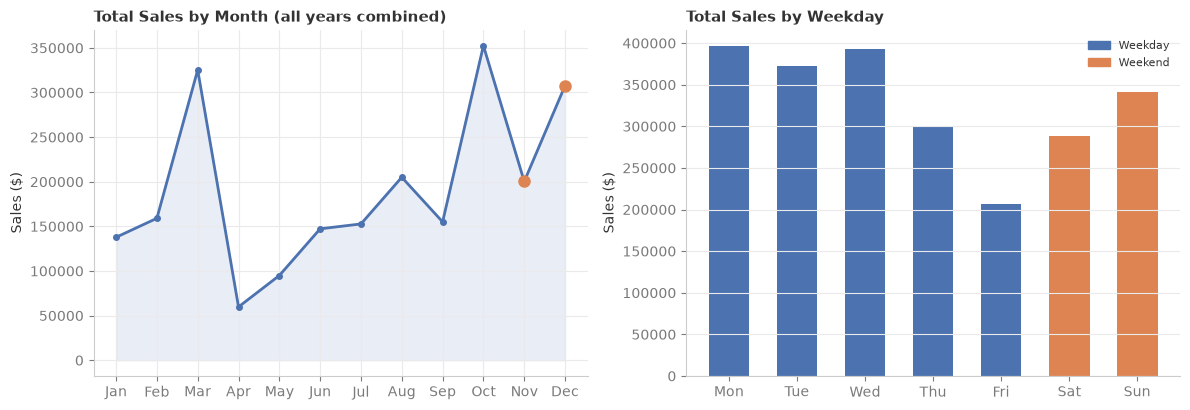

In [30]:
month_sales = df_clean.groupby("Order Month", observed=True)["Sales"].sum().sort_index()
month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_sales = df_clean.groupby("Order Weekday", observed=True)["Sales"].sum().reindex(weekday_order)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

ax = axes[0]
ax.plot(month_labels, month_sales.values, color=CATEGORICAL[0], linewidth=2, marker="o", markersize=4)
ax.fill_between(month_labels, month_sales.values, color=CATEGORICAL[0], alpha=0.12)
for i in (10, 11):  # Nov, Dec -- the year-end peak
    ax.plot(month_labels[i], month_sales.values[i], "o", color=ACCENT, markersize=8, zorder=5)
ax.set_title("Total Sales by Month (all years combined)", loc="left", fontsize=11, fontweight="bold")
ax.set_ylabel("Sales ($)")

ax = axes[1]
bar_colors = [ACCENT if d in ("Saturday", "Sunday") else CATEGORICAL[0] for d in weekday_order]
bars = ax.bar([d[:3] for d in weekday_order], weekday_sales.values, color=bar_colors, width=0.6)
ax.set_title("Total Sales by Weekday", loc="left", fontsize=11, fontweight="bold")
ax.set_ylabel("Sales ($)")
ax.grid(axis="x", visible=False)
ax.legend(
    handles=[mpatches.Patch(color=CATEGORICAL[0], label="Weekday"),
             mpatches.Patch(color=ACCENT, label="Weekend")],
    frameon=False, fontsize=8, loc="upper right",
)
plt.tight_layout()
plt.show()

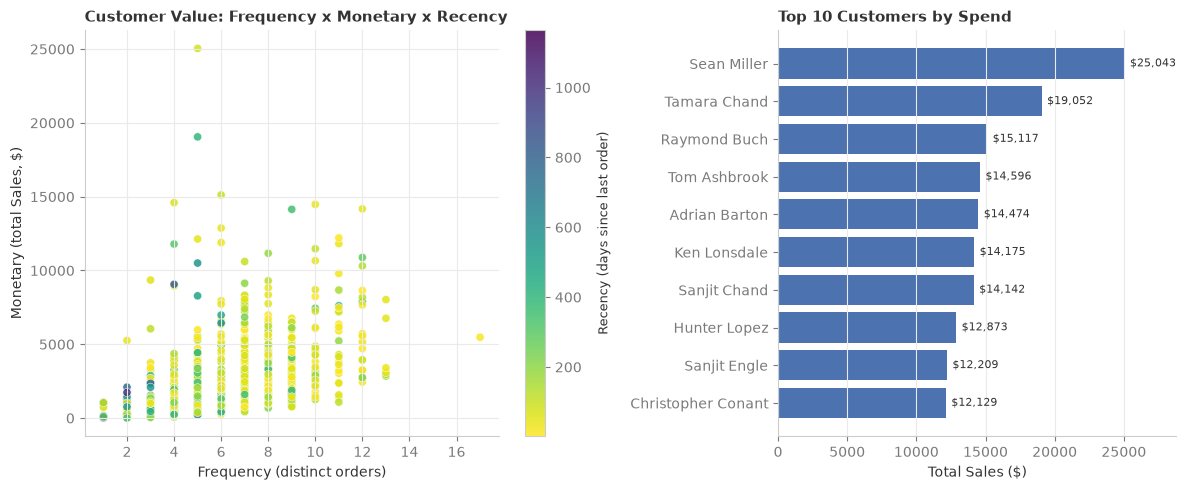

In [31]:
# Name lookup: Customer ID -> Customer Name, a label attachment (not a new aggregation)
name_lookup = df_clean[["Customer ID", "Customer Name"]].drop_duplicates().set_index("Customer ID")["Customer Name"]
rfm_named = rfm.copy()
rfm_named["Customer Name"] = name_lookup.reindex(rfm_named.index)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [1.3, 1]})

ax = axes[0]
sc = ax.scatter(rfm_named["Frequency"], rfm_named["Monetary"], c=rfm_named["Recency"],
                 cmap="viridis_r", s=35, alpha=0.85, edgecolor="white", linewidth=0.4)
cbar = plt.colorbar(sc, ax=ax)
cbar.set_label("Recency (days since last order)", fontsize=9)
ax.set_xlabel("Frequency (distinct orders)")
ax.set_ylabel("Monetary (total Sales, $)")
ax.set_title("Customer Value: Frequency x Monetary x Recency", loc="left", fontsize=11, fontweight="bold")

ax = axes[1]
top10 = rfm_named.sort_values("Monetary", ascending=False).head(10).iloc[::-1]
labels = top10["Customer Name"].fillna(top10.index.to_series())
bars = ax.barh(labels, top10["Monetary"], color=CATEGORICAL[0])
ax.set_title("Top 10 Customers by Spend", loc="left", fontsize=11, fontweight="bold")
ax.set_xlabel("Total Sales ($)")
for bar, v in zip(bars, top10["Monetary"]):
    ax.annotate(f"${v:,.0f}", xy=(v, bar.get_y() + bar.get_height() / 2),
                xytext=(4, 0), textcoords="offset points", va="center", fontsize=8)
ax.margins(x=0.15)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

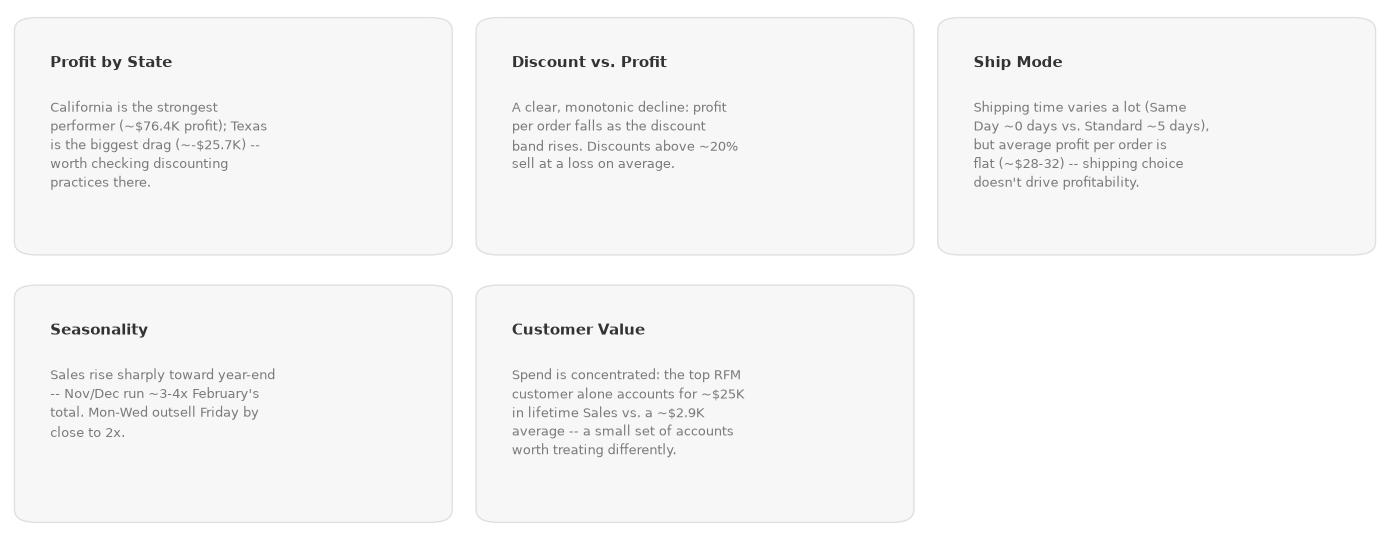

In [32]:
import textwrap

takeaways = [
    ("Profit by State", "California is the strongest performer (~$76.4K profit); Texas is the "
     "biggest drag (~-$25.7K) -- worth checking discounting practices there."),
    ("Discount vs. Profit", "A clear, monotonic decline: profit per order falls as the discount "
     "band rises. Discounts above ~20% sell at a loss on average."),
    ("Ship Mode", "Shipping time varies a lot (Same Day ~0 days vs. Standard ~5 days), but "
     "average profit per order is flat (~$28-32) -- shipping choice doesn't drive profitability."),
    ("Seasonality", "Sales rise sharply toward year-end -- Nov/Dec run ~3-4x February's total. "
     "Mon-Wed outsell Friday by close to 2x."),
    ("Customer Value", "Spend is concentrated: the top RFM customer alone accounts for ~$25K "
     "in lifetime Sales vs. a ~$2.9K average -- a small set of accounts worth treating differently."),
]

fig, axes = plt.subplots(2, 3, figsize=(14, 5.5))
axes = axes.flatten()
for ax, (title, body) in zip(axes, takeaways):
    ax.axis("off")
    ax.add_patch(FancyBboxPatch(
        (0.03, 0.05), 0.94, 0.9, boxstyle="round,pad=0.02,rounding_size=0.05",
        transform=ax.transAxes, facecolor="#F7F7F7", edgecolor="#E0E0E0", linewidth=1,
    ))
    ax.text(0.09, 0.82, title, transform=ax.transAxes, ha="left", va="top",
            fontsize=11, fontweight="bold", color=INK)
    wrapped = "\n".join(textwrap.wrap(body, width=34))
    ax.text(0.09, 0.65, wrapped, transform=ax.transAxes, ha="left", va="top",
            fontsize=9, color=MUTED, linespacing=1.5)
axes[-1].axis("off")  # 6th grid cell unused (5 takeaways)
plt.tight_layout()
plt.show()